# Classical Statistical Inference: Part 1

## Table of Content

- I. [Basic probability concepts](#I)
    * I.1 [Probability axioms](#I.1-Probability-axioms)
    * I.2 [What is a conditional probability and what is the Bayes theorem ?](#I.2-What-is-a-conditional-probability-and-what-is-the-Bayes-theorem-?)
    * I.3 [What is a random variable ?](#I.3-What-is-a-random-variable-?)
    * I.4 [What is a probability density function ?](#pdf)
    * I.4b [pdf, conditional probability and Bayes rule for bivariate distributions](#bivariate)
    * I.5 [What is a cumulative distribution function ?](#I.5-What-is-a-cumulative-distribution-function-?)
    * I.6 [Working with pdf and CDF](Basic-statistics_02.ipynb)

- X. [References and supplementary material](#X)

In [1]:
# Modules to be used in this notebook
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt
%matplotlib inline

# Our random number generator. The seed (10) is fixed so that everybody gets the same numbers.
# Change the seed (or call np.random.default_rng() without argument) to see the impact.
rng = np.random.default_rng(10)

## I Basic (probability) concepts:  <a class="anchor" id="I"></a>

First of all, let's remind us some definitions and notations, so everybody is on the same page.

In probability theory, we define the following:
- the set of all possible outcomes of an experiment is generally called **sample space** and denoted $\Omega$.
- Points in $\Omega$ are called **realisations** $\omega$ (one realisation = one possible outcome).
- An **Event** is a *subset* of $\Omega$ (a set of outcomes, $A \subset \Omega$).
- $p(A)$ is the **probability** of an event $A$. (For a continuous variable, we will see below that the probability that a value of $x$ falls in an interval of width ${\rm d}x$ around $x$ is $p(x)\,{\rm d}x$, where $p(x)$ is a probability *density*.)

**Example**: We measure the magnitude $m$ of a variable star. Then $\Omega = \mathbb{R}$ (or some plausible range such as $]-30, 40 [$, but this makes little difference in practice and $\Omega$ can in general be larger than needed). $\omega$ is a value in $\Omega$, while an event is defined by a condition on the outcomes, e.g. "the measured magnitude satisfies $15 < m \leq 15.5$", hence this *event* is $A = \,]15, 15.5]$. Note that an event *can* also be a single point (i.e. $A = \{17\}$).

If you are comfortable with your understanding of basic probability concepts, you can go directly to [Sect. I.3](#I.3-What-is-a-random-variable-?). Otherwise, the next sections are there to refresh your mind.

### I.1 Probability axioms

To qualify as a probability, $p(A)$ must satisfy the three following axioms (also called [Kolmogorov](https://en.wikipedia.org/wiki/Andrey_Kolmogorov) axioms).

1. $p(A) \geq 0$ for each $A$.
2. $p(\Omega) = 1$
3. If $A_1, A_2, A_3, ...$ are disjoint events, then
$$
p\left(\bigcup_{i=1}^{\infty} {A_i}\right) = \sum_{i=1}^{\infty} p(A_i),
$$
where $\cup$ stands for **union**.

As a consequence of these axioms, several useful rules can be derived (e.g. $p(A) \leq 1$ and $p(\emptyset) = 0$).

#### The *sum rule*:

$$
p(A \cup B) = p(A) + p(B)-p(A \cap B)
$$

where $\cap$ stands for **intersection**. Note that in some stats books, you may see $p(A \cap B)$ written $p(AB)$.

This sum rule avoids double counting the intersection when calculating the probability that *A or B (or both)* happen (i.e. $A \cup B$), as illustrated on the figure below (based on Fig. 3.1. of our reference [book](#book)). Note that $A \cap B$ is the event "*both* $A$ and $B$ happen".

#### Illustration of the *sum rule*:
![From astroML book](../Figures/Sum_of_probabilities_2.png)

#### Law of total probability:

If events $B_i$ ($i=$1, 2, ... N) are *disjoint*, and their *union* is the set of all possible outcomes (i.e. $\cup_{i=1}^N B_i = \Omega$, they form a *partition* of $\Omega$), then:

$$
p(A) = \sum_i p(A\,\cap\,B_i) = \sum_i p(A \,|\, B_i)~p(B_i)
$$

This expression is known as the **law of total probability**.

#### Conditional probability and law of total probability:

Conditional probabilities also satisfy the law of total probability. For an event $C$ with $p(C) > 0$ and the partition $B_i$ above:

$$
p(A \, | \, C) = \sum_i p(A \,|\,C \,\cap \, B_i)~p(B_i \,| C)
$$

We'll come back to conditional probabilities later.

**Note:** Those probability axioms and lemmas are accepted by both frequentist and bayesian statisticians. The difference between those "two schools" comes from the *interpretation* of the probability of an event $A$, and of conditional probabilities.

### I.2 What is a conditional probability and what is the Bayes theorem ?

#### Definition:

Assuming that $p(B) > 0$, the **conditional probability** of $A$ *given* $B$ (that we write $p(A \, | \, B)$), is defined as:

$$
p(A \, | \, B) = \frac{p(A \, \cap \, B)}{p(B)}
$$

In other words, the conditional probability of $A$ *given* $B$ is **the fraction of the cases where $B$ occurs in which $A$ occurs as well**. Having "$A$ given $B$" means that we consider events $A$ given that $B$ is true.

Rewriting the definition, *for any two events* (independent or not), the probability that *both* $A$ and $B$ happen is:
$$
p(A \cap B) = p(A \,|\, B)~ p(B) = p(B \,|\, A)~ p(A).
$$

If $A$ and $B$ are **independent** events, knowing $B$ does not change the probability of $A$, i.e. $p(A\,|\,B) = p(A)$, and therefore $p(A \cap B) = p(A)~p(B)$.

As we see here, *in general* $p(A \, | \, B) \ne p(B \, | \, A)$. The probability to have a fever given you have the flu is close to 1, but the probability you have the flu given you have a fever is surely lower than 1!

One can re-write the above expression the following way:

$$
p(A\,|\,B) = \frac{p(B\,|\,A) \, p(A)}{p(B)}
$$

This expression, devised by reverend Bayes during the 18th century, is called the **Bayes theorem**.
Note that we can see $B$ as some observation (data) and $A$ as some model parameters: Bayes' theorem then tells us how to go from "the probability of the data given the model", $p(B\,|\,A)$, to what we are really interested in, "the probability of the model given the data", $p(A\,|\,B)$. We'll discuss this idea in a future lecture.

#### Example: a rare disease and a medical test

**Question:** Let's consider a rare disease that affects 0.1\% of the population. On the other hand, let's consider a test that detects the disease in 99\% of the sick people, and that gives a positive result for 1\% of the healthy people (1\% false positive rate). If you have a positive test, what is the probability for you to be affected by this disease?

Among 1000 persons, 1 has the disease (it affects 0.1 \% of the population). The test detects 99% of the sick people, and gives 1% of false positives: => 10 people (1% of the 999 healthy ones) will be positive while healthy. You should add ~1 being positive while being effectively sick.
=> $p({\rm disease} \,|\, +) \sim 1/11 \simeq 9\%$

In [2]:
# What you are interested in is the p(disease | positive test)
# p(d | +) = p(+ | d) * p(d) / p(+)
# We have p(+ | d) = 0.99
p_B_given_A = 0.99
# We have probability of disease p(d) = 0.001
p_A = 0.001
# We have probability of positive test = p(+ | d) * p (d) + p(+ | !d) * p(!d)
p_B = 0.001 * 0.99 + (1. - 0.001) * (1 - 0.99)
p_A_given_B = p_B_given_A * p_A / p_B
p_A_given_B

0.09016393442622944

An alternative way to solve the problem is to fill the following table (aka **Contingency Table**) with the information in hand.

|             | H = Disease        |  !H = No Disease     | Sum     |
| --------------| ---------------------| ----------------------| -------------------|
| E = Test +   | $p(E\,|\,H)$ $\times$ $p(H)$ |  $p(E\,|\,!H)$ $\times$ $p(!H)$ | $p(E)$ |
| !E = Test - | $p(!E\,|\,H)$ $\times$ $p(H)$| $p(!E\,|\,!H)$ $\times$ $p(!H)$ | $p(!E)$|
| Sum | $p(H)$  | $p(!H)$ | 1 |

Let's do the calculation for a population of $n = 100000$ people.

|        | Disease         | No Disease       | Sum          |
|--------| ----------------| -----------------| -------------|
| Test + | 100 $\times$ 0.99 = 99| 99900 $\times$ (1-0.99) = 999 | $p(+)$ $\times \, n$ = 1098   |
| Test - | 100 $\times$ (1-0.99) = 1 | 99900 - 999 = 98901 | $p(-)$ $\times \, n$ = 98902 |
| Sum    | **100** $= p(d) \times n$ | **99900** = $p(!d) \times n$ | **n = 100000** |

One can start filling this table with the bold numbers, which express here the prior on getting the disease (the prevalence in the population). Then, you can fill the first row ("Test +") by multiplying each column by the corresponding probability of a positive test: the sensitivity $p(+\,|\,d) = 0.99$ for the diseased, and the false positive rate $p(+\,|\,!d) = 0.01$ for the healthy. The second row ("Test -") is then obtained as the difference between the sum row (total population of each column) and the first row. Finally, $p(d\,|\,+) = 99 / 1098 \simeq 9\%$. (You may also change the prior if, for example, you want to calculate the probability to be sick given a *second* positive test: the posterior of the first test becomes the prior of the second one.)

=> **Be careful with RARE events!** If you build an algorithm that detects securely 99% of the rare events (e.g. a gravitational lens, a supernova, a planet around a red dwarf, ...), you may still spend a lot of time observing false positives ... As a rule of thumb, when you design an algorithm that aims at finding rare objects, **you should aim for a False Positive Rate (FPR) at least smaller than or equal to the prevalence of the event**: otherwise, the false positives outnumber the true ones (in our example, FPR = 1% $\gg$ prevalence = 0.1%, hence only 9% of the positives are real).

### I.3 What is a random variable ?

In statistical inference, we are dealing with *data*. How do we link *sample space* and *events* to data ? The link is the concept of *random* (or *stochastic*) variable.

#### Definition:

Mathematically, a random variable is a *mapping*
$$
X: \Omega \to \mathbb{R}
$$
that assigns a real number $X(\omega)$ to each outcome $\omega$.

A less formal definition is simply that a random variable is a variable whose value results from the measurement of a quantity that is subject to random variations.

**Example:** You roll a die 10 times and record the sequence of outcomes, e.g. $\omega = (1, 2, 4, 2, 5, 4, 6, 3, 3, 1)$ (an *ordered* sequence, hence round brackets). You can then define $X(\omega)$ to be the *number of times you drew an even number* in the sequence $\omega$. Here the even outcomes are 2, 4, 2, 4, 6, so $X(\omega) = 5$ is the value taken by your *random variable* $X$.

Note that you can have either *continuous* or *discrete* random variables. If the set of values the variable can take is countable, the variable is discrete. It is continuous otherwise.

**Warning**, a random variable is *NOT* like a typical mathematical variable as it can take *different values* (each with an associated probability). In the literature, you will generally find random variables written with *CAPITAL* letters, and their particular *realisation* with *lowercase* letters. A realisation of a random variable is also called a "random variate".

**Random variables with numpy**

In numpy there is a sub-module called `random` that contains many functions that involve random selection. The recommended way to use it is to create **once** a *random number generator* object (this is the `rng` created in the first cell of this notebook), and then to call its methods:

```python
rng = np.random.default_rng(10)   # 10 is the seed
```

The generator `rng` has an internal state that evolves each time you ask for a random number: two successive calls give different numbers, but the same seed always generates the same stream of numbers (this makes your results *reproducible*). Re-running a cell that uses `rng` does not give the same numbers again, because `rng` is not re-initialised: to restart from scratch, re-run the cell where `rng` is created.

In particular there is a method `choice` that allows you to make a choice at random. It picks one item at random from an array, and it is equally likely to pick any of the items. The function call is `rng.choice(array_name)`, where `array_name` is the name of the array from which to make the choice.

In [3]:
# Let's build a small array with classification of objects on a CCD:
class_phot = np.array(['star', 'galaxy', 'galaxy', 'star', 'star'])
rng.choice(class_phot)

np.str_('star')

If you re-run the above cell multiple times, you will see that the output changes, because the output is taken at random. If you provide a second argument (`size = n`), it will repeat the process $n$ times. In practice, this method allows you to *generate a random sample* from a 1-D array. You can add a third argument that specifies if you allow replacement or not: `replace=False` means that a given element of the array can only be drawn once in the output (**Note:** `replace=True` is the default).

In [4]:
rng.choice(class_phot, size=3)

array(['star', 'galaxy', 'galaxy'], dtype='<U6')

In [5]:
# Use e.g. np.arange(5) to compare the behaviour with replace=True / replace=False
a = np.arange(5)
rng.choice(a, replace=False, size=2)

array([3, 4])

In [6]:
# With replace=True, the same value can appear several times (and size can even exceed the array size)
rng.choice(a, replace=True, size=3)

array([0, 4, 2])

In [7]:
# If size > size(a), you cannot generate a random sample with choice and replace=False (it does not make sense)
try:
    rng.choice(a, replace=False, size=6)
except ValueError as err:
    print('ValueError:', err)

ValueError: Cannot take a larger sample than population when replace is False


Other important methods of the generator `rng` are:
- `rng.random(n)`: generate an array of $n$ random floats drawn from a uniform distribution on $[0, 1)$.
- `rng.integers(low, high, size)`: generate an array of random integers between `low` (included) and `high` (**excluded**).
- `rng.permutation(array_name)`: return a copy of the original array with elements permuted (along the first axis of the array).
- `rng.normal(loc, scale, size)`, `rng.standard_normal(size)`, `rng.poisson(lam, size)`, ...: draw directly from common distributions (we will rather use `scipy.stats` below).

**Note: the `np.random.xxx` functions called "on the fly" (legacy interface)**

You will see in many tutorials and older codes calls such as `np.random.seed(10)`, `np.random.rand(3)`, `np.random.randint(0, 2, size=1000)`, `np.random.choice(...)`. This is also valid and still works. These functions all use *one hidden, global* generator (a `RandomState` object using the Mersenne-Twister algorithm). It is simple for a quick test, but it is easy to get confused with the seed: `np.random.seed` acts on a global state that every piece of code (including the libraries you import) can modify, and it has no effect on a generator you created with `default_rng`. The explicit object `rng = np.random.default_rng(seed)` is easier to follow: you see where the random numbers come from, you can have several independent generators, and you can pass `rng` to functions. The correspondence between the two interfaces is:

| legacy (global) | with a generator `rng` |
|---|---|
| `np.random.seed(10)` | `rng = np.random.default_rng(10)` |
| `np.random.rand(n)` | `rng.random(n)` |
| `np.random.randint(low, high, size)` | `rng.integers(low, high, size)` |
| `np.random.choice(a, ...)` | `rng.choice(a, ...)` |
| `np.random.permutation(a)` | `rng.permutation(a)` |

The same seed does **not** give the same numbers with the two interfaces (different algorithms: Mersenne-Twister for the legacy one, PCG64 for `default_rng`).

**Exercise**

Create a 2D array of 10 rows and 7 columns (with random integer values).
- (1) Use `choice` to select at random 5 different rows.
- (2) Use `choice` to select at random 3 different columns.
- (3) Create a 1-D array representing the result of 1000 coin tosses (set value `0` for head and `1` for tail using the random integers generator). Plot the histogram of their values (using `matplotlib.pyplot.hist`; note that you can set the number of bins by setting the argument `bins = value`). Set the argument `density` of `hist()` to the values True and False. What is the difference of behaviour ?
- (4) Permute the rows of your 2d array and compare with the original. Permute (=shuffle) the elements of the first row of your original array.
- (5) Create an array `a` of 10 integers between 0 and 9 with your generator. Redo this operation and save it into an array `b`. Compare `a` and `b`. How should you proceed to have 2 identical arrays ?

In [8]:
# We can create the 2D array in 2 steps, creating first a 1D vector of 70 integers
# (10 rows * 7 columns) = 70 elements, and subsequently reshape
array_1d = rng.integers(low=0, high=100, size=10 * 7)
print('Shape of 1D', array_1d.shape)
array2d = array_1d.reshape((10, 7))
print('Shape of 2D array', array2d.shape)

Shape of 1D (70,)
Shape of 2D array (10, 7)


In [9]:
# Note that in the above example the 2 arrays have the same size
array2d.size, array_1d.size

(70, 70)

In [10]:
# Now that you understood the step-by-step, you can create the array more concisely, reshaping directly
array_2d = rng.integers(low=0, high=100, size=10 * 7).reshape((10, 7))
array_2d

array([[77, 83,  6, 77, 11, 33,  8],
       [14, 48, 45, 35, 43, 42, 57],
       [62, 37, 75, 63, 48, 11, 83],
       [23, 33, 76, 85, 98, 82, 80],
       [73, 84, 56, 79, 24, 45, 79],
       [73, 42, 57, 36, 45,  3, 27],
       [74, 86, 80,  6, 15, 81, 65],
       [88, 46, 42, 24, 83, 15, 34],
       [ 6, 51, 60, 54, 54, 19, 37],
       [33, 68, 27, 62, 45, 96, 67]])

In [11]:
# Asking for more rows (15) than available (10) without replacement is impossible:
id_rows = np.arange(10)
try:
    rng.choice(id_rows, 15, replace=False)
except ValueError as err:
    print('ValueError:', err)

ValueError: Cannot take a larger sample than population when replace is False


In [12]:
# (1) Select at random 5 DIFFERENT rows  -> replace=False (the default is replace=True !)
id_rows, id_cols = np.arange(10), np.arange(7)
rows_id = rng.choice(id_rows, 5, replace=False)   # ids of 5 random rows
print('The 5 random rows are:', rows_id)
array_2d[rows_id, :]

The 5 random rows are: [8 9 4 1 2]


array([[ 6, 51, 60, 54, 54, 19, 37],
       [33, 68, 27, 62, 45, 96, 67],
       [73, 84, 56, 79, 24, 45, 79],
       [14, 48, 45, 35, 43, 42, 57],
       [62, 37, 75, 63, 48, 11, 83]])

In [13]:
# (2) Select 3 different columns ids
cols_id = rng.choice(id_cols, 3, replace=False)   # ids of 3 random cols
print('The 3 random cols are:', cols_id)
array_2d[:, cols_id]

The 3 random cols are: [3 1 6]


array([[77, 83,  8],
       [35, 48, 57],
       [63, 37, 83],
       [85, 33, 80],
       [79, 84, 79],
       [36, 42, 27],
       [ 6, 86, 65],
       [24, 46, 34],
       [54, 51, 37],
       [62, 68, 67]])

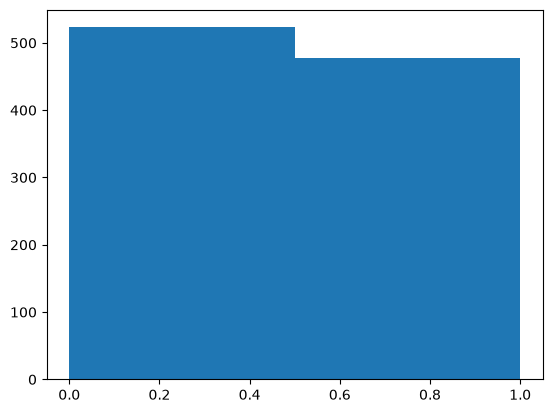

In [14]:
# (3) Create a 1-D array representing the result of 1000 coin tosses
# (set value `0` for head and `1` for tail using the random integers generator).
# Plot the histogram of their values (using `matplotlib.pyplot.hist`;
# Note that you can set the number of bins by setting the argument `bins = value`).
# Set the argument `density` of `hist()` to values True and False. What is the difference of behaviour ?
tosses = rng.integers(0, 2, 1000)      # upper bound 2 is excluded
xbin, ybins, info_toss = plt.hist(tosses, bins=2)

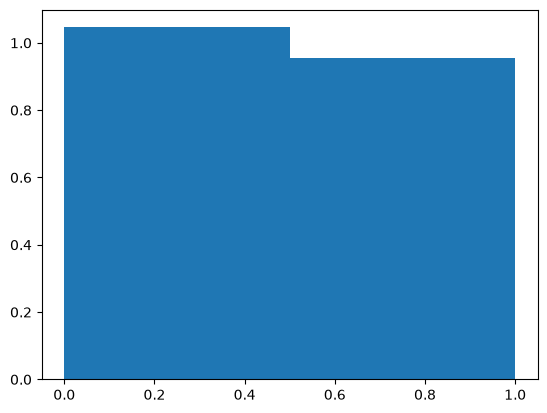

In [15]:
xbin, ybins, info_toss = plt.hist(tosses, bins=2, density=True)

In [16]:
# (4) Permutation of the rows of my 2d array (the original array is not modified)
permuted = rng.permutation(array_2d)
print('Permuted:\n', permuted)
print('Original:\n', array_2d)

Permuted:
 [[77 83  6 77 11 33  8]
 [ 6 51 60 54 54 19 37]
 [88 46 42 24 83 15 34]
 [14 48 45 35 43 42 57]
 [62 37 75 63 48 11 83]
 [73 42 57 36 45  3 27]
 [74 86 80  6 15 81 65]
 [23 33 76 85 98 82 80]
 [73 84 56 79 24 45 79]
 [33 68 27 62 45 96 67]]
Original:
 [[77 83  6 77 11 33  8]
 [14 48 45 35 43 42 57]
 [62 37 75 63 48 11 83]
 [23 33 76 85 98 82 80]
 [73 84 56 79 24 45 79]
 [73 42 57 36 45  3 27]
 [74 86 80  6 15 81 65]
 [88 46 42 24 83 15 34]
 [ 6 51 60 54 54 19 37]
 [33 68 27 62 45 96 67]]


In [17]:
# Permutation of the elements of the first row of my original array
rng.permutation(array_2d[0, :])

array([83, 77, 77, 11,  8,  6, 33])

In [18]:
# (5) Create an array `a` of 10 integers between 0 and 9. Redo this operation and save it into an array `b`.
# Compare `a` and `b`.
a = rng.integers(0, 10, 10)
b = rng.integers(0, 10, 10)
a, b

(array([8, 1, 3, 2, 2, 4, 7, 1, 8, 5]), array([8, 1, 0, 3, 3, 7, 1, 4, 5, 2]))

In [19]:
# How should you proceed to have 2 identical arrays ?
# The generator continues its stream of numbers: to get a = b, we need to start from the same seed,
# i.e. to create 2 generators with the same seed (or to re-create the generator before each draw).
rng_a = np.random.default_rng(10)
a = rng_a.integers(0, 10, 10)
rng_b = np.random.default_rng(10)
b = rng_b.integers(0, 10, 10)
a, b

(array([7, 9, 2, 2, 7, 8, 5, 1, 8, 5]), array([7, 9, 2, 2, 7, 8, 5, 1, 8, 5]))

### I.4 What is a probability density function ? <a class="anchor" id="pdf"></a>

We will generally be dealing with probability *densities*, that is, $p(x)\,{\rm d}x$ is the probability of a value falling between $x$ and $x \,+\, {\rm d}x$.

Remember the histogram counting your measurements (cf. exercise (3) above), with `density=True`. The heights $p_i$ of the bins are then such that $\sum_i p_i\, \delta x_i = 1$ (where $\delta x_i$ is the bin width). The histogram is thus an *estimate of the probability density* from a finite sample. (For a discrete variable, the analogue of a density is the probability mass function, see below.)

Probability densities are normalised such that the union of all possible events has a probability of unity; mathematically that criterion looks like this:

$$
\int p(x)\,{\rm{d}}x = 1
$$

Among other things, consider the **units** implied by this expression: because probability is dimensionless, the *units of $p(x)$* must be the *inverse of the units of $x$*. This can be very useful to keep in mind as you manipulate probabilistic expressions! It also means that a density is **not** a probability: it can be larger than 1 (see the example below), and for a continuous variable the probability of getting exactly one value $x_0$ is zero. Only the integral of the density over an interval is a probability.

#### (Formal) definition:

Let's first define a function such that $H_X(x_0)$ expresses the probability for a random variable $X \leq x_0$. We would have, by definition, $H_X(-\infty) = 0$ and $H_X(+\infty) = 1$.
We can then define the **probability density function** (aka **pdf**) $h_X(x)$ as:

$$
h_X(x) = \frac{{\rm d}H_X(x)}{{\rm d}x}
$$

It results that:

$$
p(X\, \in [x, x+{\rm d}x[) \, = \, H_X(x+{\rm d}x) - H_X(x)  = h_X(x)\, {\rm d}x
$$

Hence, the **probability density function** (aka **pdf**) $h_X(x)$ is a function that quantifies the probability that the value of a random variable $X$ falls between $x$ and $x+{\rm d}x$. That probability equals $h_X(x)\,{\rm d}x$. The term *probability distribution* or *differential distribution function* is also used (especially by astronomers ...).

We can generalise to multiple variables. The probability for $x < x_0$, and $y < y_0$ is $H(x_0, y_0)$ and the associated pdf is $h(x_0, y_0)\, {\rm d}x \, {\rm d}y$. The two random variables are independent if $h(x, y) = f(x)~g(y)$ for all values of $x$ and $y$. Note that when two independent random variables are *independently* drawn from the same distribution (i.e. $h(x, y) = f(x)~f(y)$), one speaks of **independent identically distributed** (iid) random variables. In this case, we obviously have $p(x, y)\,=\,p(x)~p(y)$.

**Example:**
You know several pdfs, such as the *uniform* and the *normal* (aka gaussian) pdf.
A *uniform* pdf on $[a, b]$ is such that:

$$
\begin{array}{lll}
   h(x)    & = \dfrac{1}{b-a} & {\rm if}\;\, a\,\leq\,x\,\leq\,b \\[2mm]
   h(x)    & = 0 & {\rm otherwise}
\end{array}
$$

The gaussian pdf of mean $\mu$ and standard deviation $\sigma$ is:

$$
h(x \,|\, \mu, \sigma) = \frac{1}{\sqrt{2\pi}\,\sigma} \exp \left( -\frac{1}{2}\frac{(x-\mu)^2}{\sigma^2}\right)
$$

It is important to keep in mind that the *integral* of $h(x)$ over its domain has to be 1, otherwise we do not have a properly normalised pdf. This explains the normalisation factor $1/(\sqrt{2\pi}\,\sigma)$ in front of the gaussian pdf. Note that this does **not** mean that $h(x) \leq 1$: for the uniform pdf with $b - a = 0.1$ we have $h(x) = 10$ on $[a,b]$, and a gaussian with $\sigma < 1/\sqrt{2\pi} \approx 0.4$ has a maximum larger than 1. Only probabilities (areas under the pdf) are bounded by 1.

#### Definition addendum:

In cases where random variables are **discrete**, $H_X(x)$ is a staircase function (it is not differentiable: its derivative is an ensemble of delta functions), and one rather speaks of **probability mass function** (pmf). In this case, $X$ may take a (finite or countable) number of values $\{x_1, x_2, ...\}$ and the mass function is simply:
$$
h_X(x_i) = p(X\,=\,x_i), \qquad \sum_i h_X(x_i) = 1
$$

Here the values of the pmf *are* probabilities (so they are between 0 and 1). The Poisson and Bernoulli distributions are examples of pmf.

As the statistical context of the lectures is clear, we also generally drop the index "X", that is there to stress that we speak of a function of a random variable (and not of a normal mathematical variable) when writing the pdf. Hence, we will write $h(x)$ instead of $h_X(x)$.

#### Relevance of pdf for statistical inference:

The probability density function is at the heart of data mining, and data analysis in general. A key question is indeed to figure out what is the pdf $h_X(x)$ that is behind a set of random variables (directly observed or predicted by a model fed by some data). I.e. we generally try to answer the question "From which pdf $h(x)$ are my $x$ drawn?". In Bayesian inference, one tries to derive the (posterior) pdf associated to a quantity. Why are we interested in those? Because they tell us something about the probability of an event/observation to occur or help us to figure out whether a physical model is sensible *given* the observations in hand.

Following the convention of our [reference book](#book), we use $h(x)$ when we refer to the *true* pdf (or **population** pdf), and $f(x)$ when we refer to its *data* derived estimate (**empirical** pdf). Since $x$ are generally measured with errors, it may be that $f(x)$ does not tend to $h(x)$ even for an infinite number of measurements (we end up with a "blurred" or "broadened" version of the pdf). Because $h(x)\,{\rm d}x$ gives the probability that $x$ falls in an (infinitely) small interval $[x, x+{\rm{d}}x]$, the pdf is also sometimes written $p(x)$ (cf. Chapter 3 of our [reference book](#book)).

As we said, $f(x)$ is a *model* of the *true* distribution $h(x)$. We observe data points that are *samples* of the true distribution $h(x)$. In general, we do not know $h(x)$ and we have to guess its functional form. This functional form can either be "parametric" (e.g. a gaussian) or "non parametric" (e.g. a sum of small gaussians that mimic a more complex pdf).

**Examples of pdf in scientific papers:**

- Marginalised pdf on H0 in Fig. 4 Bonvin et al. 2017 http://arxiv.org/abs/1607.01790
![ima](../Figures/HOLICOW_pdf.png)
- 2D PDF on pairs of gravitational lensing parameters in Fig. 7 of Hartley et al. 2019 http://arxiv.org/abs/1901.05791v1
- Probability density function for the frequency of Jovian-mass planets around intermediate-mass stars interior to $\sim$3 AU: Figure 13 of Bowler et al. 2010 https://arxiv.org/abs/0912.0518

#### Python implementation

A large number of distribution functions are implemented in `scipy.stats`, such as the binomial distribution, Poisson distribution, gaussian distribution, chi2, Cauchy distribution, ... To use them you simply have to:

**Method 1**

You work in two steps. It allows you to calculate multiple quantities associated to a distribution.

- 1) **Create an instance of an object "distribution"** with some fixed parameters, e.g.:

``` python
# Create a gaussian function with parameters mu=0, sigma=2
g = scipy.stats.norm(0, 2)

# Poisson distribution for 10 events
pois = scipy.stats.poisson(10)
```

**Note:** The help of `scipy.stats` distributions refers to the `loc` and `scale` keywords. Every continuous distribution is defined in a *standardised form*, and `loc` and `scale` shift and stretch it: if $Z$ follows the standardised distribution (`loc=0`, `scale=1`), then $X = {\rm loc} + {\rm scale}\times Z$ follows `dist(loc, scale)`, with pdf $h_X(x) = h_Z\!\left(\frac{x-{\rm loc}}{\rm scale}\right)/{\rm scale}$. For the gaussian `norm` (only!), `loc` is the mean and `scale` the standard deviation. For `uniform`, `loc` is the lower bound $a$ and `scale` the *width* $b-a$ (so `uniform(loc=a, scale=b-a)` is uniform on $[a,b]$, with mean `loc + scale/2`); for `expon`, `loc` is the starting point and `scale` is $1/\lambda$ (mean `loc + scale`). Discrete distributions only have a `loc` (a shift of the integers $k$).

In [20]:
g = scipy.stats.norm(0, 2)   # Equivalently use: g = scipy.stats.norm(loc=0, scale=2.)

In [21]:
# loc and scale are NOT always the mean and the std: illustration with loc=2, scale=3
for name, dist in [('norm', scipy.stats.norm), ('uniform', scipy.stats.uniform), ('expon', scipy.stats.expon)]:
    d = dist(loc=2, scale=3)
    print('%-8s mean = %5.2f   std = %5.2f' % (name, d.mean(), d.std()))

norm     mean =  2.00   std =  3.00
uniform  mean =  3.50   std =  0.87
expon    mean =  5.00   std =  3.00


- 2) Calculate **properties associated to (the instance of) this object** using a set of *specific methods*. For the pdf, use the method `pdf`:

``` python
# Evaluate the pdf / pmf associated to our objects g / pois at "position" x / k

g_pdf = g.pdf(x)        # x is either a numpy array or a specific value

pois_pmf = pois.pmf(k)  # k is an array of integers or a specific value
```

**Method 2**

You can generate a `pdf` associated to a normal distribution with a single command line:

``` python
x = np.arange(-10, 10, 0.1)   # Create an array over which you want to evaluate the pdf

y = scipy.stats.norm.pdf(x, loc=0, scale=2)   # for a gaussian of mean mu=0, sigma=2
```

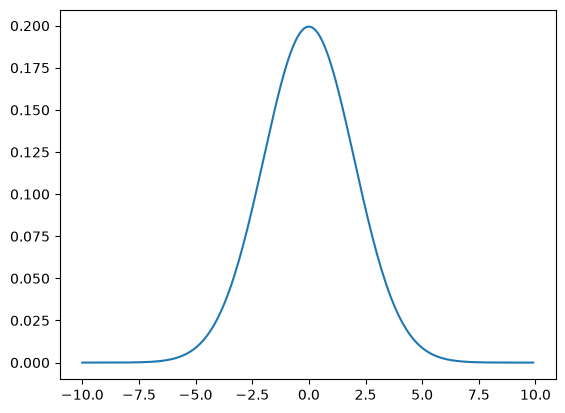

In [22]:
# Use this cell to plot the pdf associated with the gaussian distribution you have generated above
x = np.arange(-10, 10, 0.1)
g_pdf = g.pdf(x)
plt.plot(x, g_pdf)

In [23]:
# Density is not a probability: a narrow gaussian has a pdf larger than 1, but its integral is 1
narrow = scipy.stats.norm(loc=0, scale=0.1)
xx = np.arange(-1, 1, 0.001)
print('pdf at 0: %.2f   integral of the pdf: %.3f' % (narrow.pdf(0), np.sum(narrow.pdf(xx) * 0.001)))
print('p(-0.01 < X < 0.01) = %.3f  (~ pdf(0) * width = %.3f), and p(X = 0) = 0' % (narrow.cdf(0.01) - narrow.cdf(-0.01), narrow.pdf(0) * 0.02))

pdf at 0: 3.99   integral of the pdf: 1.000
p(-0.01 < X < 0.01) = 0.080  (~ pdf(0) * width = 0.080), and p(X = 0) = 0


Sum of the pmf: 1.000 ; maximum: 0.125  (a pmf gives probabilities, so it is always <= 1)


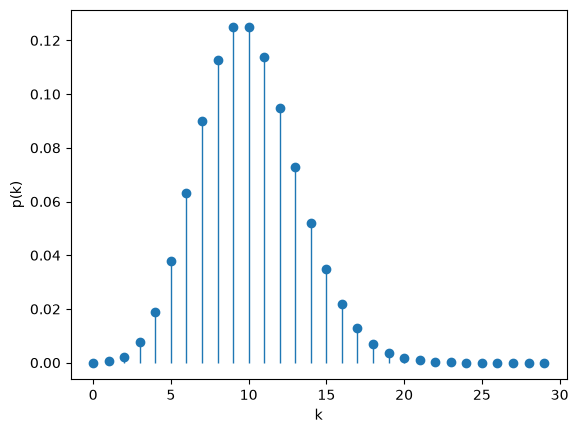

In [24]:
# Let's now do it for a probability mass function
pois = scipy.stats.poisson(10)
k = np.arange(30)
pois_pmf = pois.pmf(k)
plt.plot(k, pois_pmf, 'o')            # a pmf only exists at integer values: points and sticks,
plt.vlines(k, 0, pois_pmf, lw=1)      # not a continuous line
plt.xlabel('k'); plt.ylabel('p(k)')
print('Sum of the pmf: %.3f ; maximum: %.3f  (a pmf gives probabilities, so it is always <= 1)' % (pois.pmf(np.arange(100)).sum(), pois_pmf.max()))

Other properties of the object (mean, std, moments, ...) can be calculated as we will see later. It is also possible to draw a random sample that follows the distribution we want to use, using the method `rvs()` (random variates). To use the generator `rng` (so that the sample is reproducible and consistent with the rest of the notebook), pass it with the argument `random_state`:

``` python
# Generate a sample of 1000 points drawn from a gaussian distribution:
g_sample = g.rvs(size=1000, random_state=rng)

# Generate a sample of 10 points drawn from a Poisson distribution:
pois_sample = pois.rvs(size=10, random_state=rng)
```

(If you do not provide `random_state`, scipy uses the legacy global generator of numpy.)

See Sect. 3.2 of our reference [book](#book) for an overview of the main distributions implemented in scipy.

**Exercises:**

- Generate a random sample of $n$ points drawn from the gaussian distribution you defined above (compare $n$ = 10, 100, 1000).
- Plot a histogram with the sample of points you have generated.
- Plot a canonical gaussian pdf (width = 1) and overplot a horizontal line showing its FWHM.
- Print on the screen the value of the FWHM and compare with the value you expect for a canonical 1D-gaussian (FWHM $= 2 \sqrt{2 \ln 2}\,\sigma$)

TIP: Keep the value of the FWHM of a gaussian in mind, you may have to use it often.

In [25]:
# Use this cell to generate a random sample of points drawn from the gaussian distribution you defined above
# Plot a histogram with the sample of points you have generated.
g = scipy.stats.norm(0, 2)   # I copy the gaussian definition for legibility
sample_1 = g.rvs(size=10, random_state=rng)
sample_2 = g.rvs(size=100, random_state=rng)
sample_3 = g.rvs(size=1000, random_state=rng)

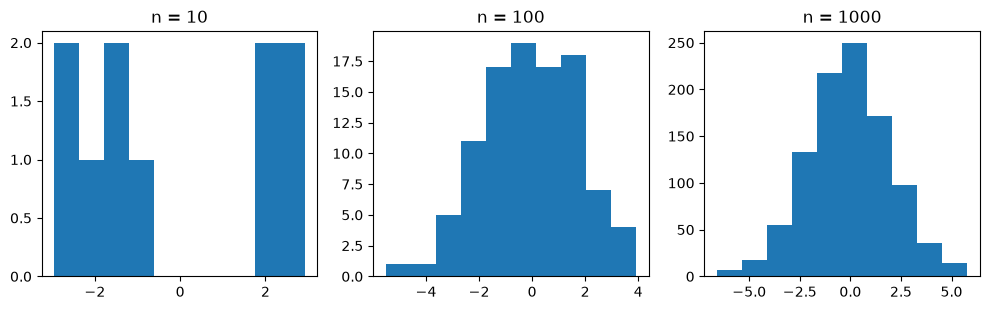

In [26]:
# plotting the histogram
f, ax = plt.subplots(ncols=3, figsize=(10, 3.2))  # I will plot the histograms in 3 separate panels
for i, sample in enumerate([sample_1, sample_2, sample_3]):
    ax[i].hist(sample, bins=10)
    ax[i].set_title('n = %i' % len(sample))
plt.tight_layout()

It is interesting to notice that even with a sample of 10 points, it is hard to guess the original distribution.

Value of the FWHM: 2.3548
Theoretical value: 2.3548


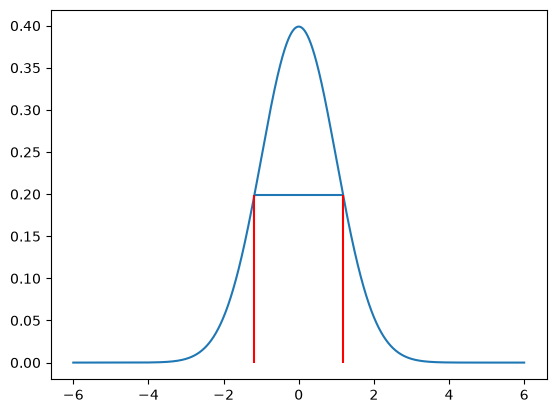

In [27]:
# Illustration of a canonical gaussian pdf and overplot of a line showing its FWHM
g = scipy.stats.norm(0, 1)
x = np.arange(-6, 6, 0.0001)
y = g.pdf(x)
plt.plot(x, y)
id_max = y.argmax()  # ID of the maximum of the function
# find the points corresponding to Half the maximum:
# first index where the pdf is above half of its maximum (np.searchsorted would require a sorted array)
left_id = np.argmax(y >= y.max() / 2)      # ID of the left half maximum
right_id = id_max + (id_max - left_id)     # We make use of the symmetric form of the gaussian profile
plt.hlines(y.max() / 2, x[left_id], x[right_id])
plt.vlines(-2.3548/2, 0, y.max()/2, color='red'), plt.vlines(2.3548/2, 0, y.max()/2, color='red')
print('Value of the FWHM: %.4f' % (x[right_id] - x[left_id]))
print('Theoretical value: %.4f' % (2. * np.sqrt(2. * np.log(2))))

### I.4b pdf, conditional probability and Bayes rule for bivariate distributions:  <a class="anchor" id="bivariate"></a>

This section (I.4b) is *not* mandatory for the course SPAT0002. It is provided for completeness.

When we have 2 *continuous random variables*, we can write (with $p$ denoting here the joint, conditional and marginal *densities*):

$$
p(x,y) = p(x\,|\,y) \, p(y) = p(y\,|\,x) \, p(x)
$$

Such a distribution of 2 random variables is called a **bivariate distribution**.

The *marginal distribution* $p(x)$ (resp. $p(y)$) is obtained by integrating $p(x, y)$ over all the values of $y$ (resp. $x$):

$$
p(x) = \int p(x,y) \, {\rm d}y
$$
$$
p(y) = \int p(x,y) \, {\rm d}x
$$

Hence, we have:

$$
p(x)= \int p(x\,|\,y) \, p(y)  \, {\rm d}y
$$

$$
p(y\,|\,x) = \frac{p(x\, | \, y) \, p(y)}{p(x)} = \frac{p(x\, | \, y) \, p(y)}{\int p(x\,|\,y) \, p(y)  \, {\rm d}y}
$$

For a discrete variable (let's say $\{y_j\}$ with $j=1, ..., M$), the integral becomes a sum:

$$
p(y_j\,|\,x) = \frac{p(x\, | \, y_j) \, p(y_j)}{p(x)} = \frac{p(x\, | \, y_j) \, p(y_j)}{\sum_{j=1}^M \, p(x\,|\,y_j) \, p(y_j) }
$$

For bi-(multi-)variate distributions, $p(x,y)$, one also defines the **covariance**:

$$
{\rm Cov}(x,y) = \langle (x - \langle x \rangle)(y - \langle y \rangle) \rangle = \int_{-\infty}^{+\infty}\int_{-\infty}^{+\infty} (x - \langle x \rangle)(y - \langle y \rangle)\,p(x,y)\, {\rm d}x\,{\rm d}y
$$

(which simplifies to $\langle xy \rangle$ if $\langle x \rangle = \langle y \rangle = 0$). We can also define a dimensionless **correlation coefficient**:

$$
r = \frac{{\rm Cov}(x,y)}{\sqrt{{\rm Var}(x)\,{\rm Var}(y)}} = \frac{{\rm Cov}(x,y)}{\sigma_x \sigma_y}, \qquad -1 \leq r \leq 1.
$$

If $r = 1$ ($r = -1$) the two random variables are perfectly (anti-)correlated (i.e. linearly related). If the variables are *independent*, then $r=0$. The reverse is not true in general: $r = 0$ only means *uncorrelated* (no *linear* dependence); for jointly gaussian variables, uncorrelated does imply independent.

#### Example

Use of `scipy.stats.multivariate_normal()` for a multivariate gaussian distribution. Beware that the second argument (`cov`) is the *covariance matrix*, whose diagonal elements are the **variances** ($\sigma_x^2$, $\sigma_y^2$), not the standard deviations.

Integral of the marginal: 0.993 (slightly < 1 because the grid cuts the tails) ; integral of the conditional: 1.000


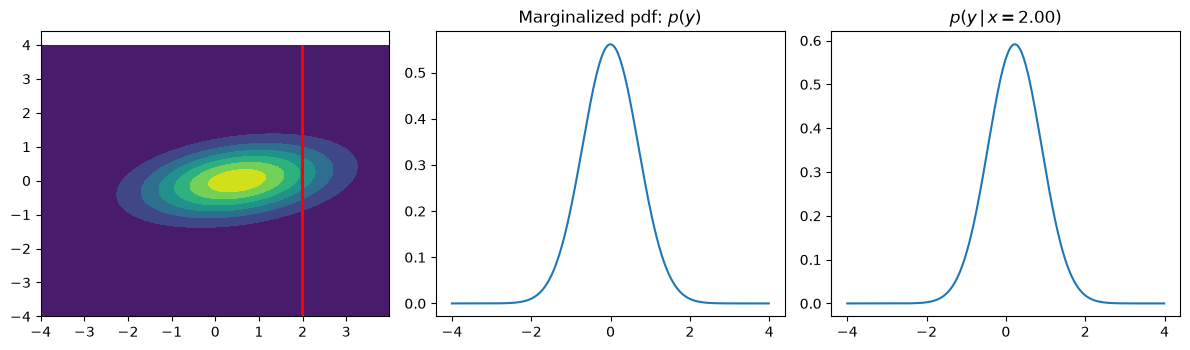

In [28]:
step = 0.01
x, y = np.arange(-4., 4., step), np.arange(-4, 4., step)
X, Y = np.meshgrid(x, y)
# X, Y = np.mgrid[-4:4:.01, -4:4:.01]    # Alternative command to generate a meshgrid!
# I now create a 3D array containing the X and Y coordinates
pos = np.zeros(X.shape + (2,))
pos[:, :, 0] = X
pos[:, :, 1] = Y
# define xid: index of x array for which I want to know the conditional pdf p(y | x)
xid = 600
# Non isotropic bivariate distribution
n_2d = scipy.stats.multivariate_normal(mean=[0.5, 0.], cov=[[2.0, 0.3], [0.3, 0.5]])
f, ax = plt.subplots(figsize=(12, 3.6), ncols=3)
ax[0].contourf(X, Y, n_2d.pdf(pos))
ax[0].vlines(x[xid] - step/2., -4, 4, color='red')
ax[0].vlines(x[xid] + step/2., -4, 4, color='red')
# Calculates the marginalised pdf: sum over the x axis (axis=1), times dx so that the integral is 1
ax[1].plot(y, n_2d.pdf(pos).sum(axis=1) * step)
ax[1].set_title('Marginalized pdf: $p(y)$')
# Plot p(y | x=xval) = p(x, y) / p(x): the renormalisation by p(x) at x=xid makes the integral over y equal to 1
ax[2].plot(y, n_2d.pdf(pos)[:, xid] / (n_2d.pdf(pos).sum(axis=0)[xid] * step))
ax[2].set_title('$p(y\\,|\\,x =%.2f )$' % x[xid])
plt.tight_layout()
print('Integral of the marginal: %.3f (slightly < 1 because the grid cuts the tails) ; integral of the conditional: %.3f' % (
    (n_2d.pdf(pos).sum(axis=1) * step).sum() * step,
    (n_2d.pdf(pos)[:, xid] / (n_2d.pdf(pos).sum(axis=0)[xid] * step)).sum() * step))

In [29]:
cov = np.array([[2.0, 0.3], [0.3, 0.5]])
# the diagonal elements of the covariance matrix are the VARIANCES sigma_x^2 and sigma_y^2
print('Variances:', cov[0, 0], cov[1, 1], '  standard deviations: %.3f, %.3f' % (np.sqrt(cov[0, 0]), np.sqrt(cov[1, 1])))
# correlation coefficient r = Cov(x, y) / (sigma_x * sigma_y)
print('Correlation coefficient r = %.3f' % (cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])))

Variances: 2.0 0.5   standard deviations: 1.414, 0.707
Correlation coefficient r = 0.300


### I.5 What is a cumulative distribution function ?

The *integral of a pdf* is called **cumulative distribution function**.
$$
p(X \leq x) = H(x) = \int_{-\infty}^{x}\, h(x') \, {\rm d}x'
$$

Hence, the CDF is basically the function $H_X(x)$ we have defined in the first place to introduce the pdf.

By definition, $H$ increases from $H(-\infty) = 0$ to $H(+\infty) = 1$ (this is the normalisation of the pdf).

Let's visualise the CDF $H(x_0) = p(X \leq x_0)$, in the case of a gaussian PDF. We see that this is the area below the PDF between $-\infty$ and $x_0$.

(-4.0, 4.0)

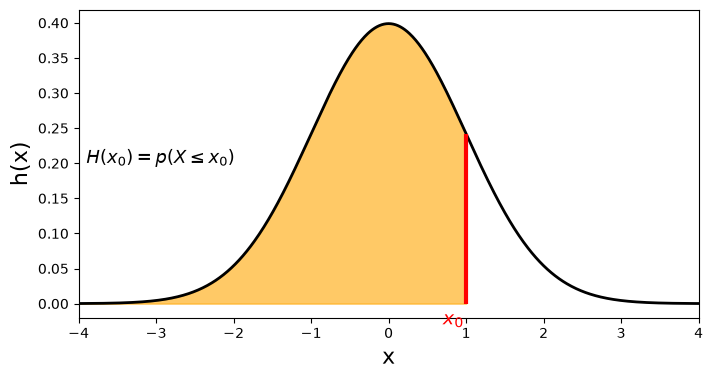

In [30]:
x = np.arange(-6, 6, 0.01)
x0 = 1.   # let's take x0 = 1
id_x0 = np.searchsorted(x, x0)
g = scipy.stats.norm(loc=0, scale=1)
f, ax = plt.subplots(ncols=1, figsize=(8, 4))
ax.plot(x, g.pdf(x), color='black', lw=2)
ax.vlines(x0, 0, g.pdf(x0), color='red', lw=3)
ax.fill_between(x[:id_x0], 0, g.pdf(x[:id_x0]), color='orange', alpha=0.6)
ax.set_ylabel('h(x)', size=16)
ax.set_xlabel('x', size=16)
ax.text(x0 - 0.3, -0.03, r'$x_0$', size=14, color='red')
ax.text(-3.9, 0.2, r'$H(x_0) = p(X \leq x_0)$', size=13)
ax.set_xlim(-4, 4)

The CDF provides a direct way to calculate the probability for the value of a random variable $X$ to be between 2 values $x_1$ and $x_2$. If $x_1 < x_2$, then $p(x_1 < X \leq x_2) = H(x_2) - H(x_1)$. On the above figure, this would be the difference of the area up to $x_2$ minus the area up to $x_1$.

Hence, you know how to derive the *p% quantile* $q_p$ of a distribution, defined as:

$$
\frac{p}{100} = \int_{-\infty}^{q_p} h(x)\, {\rm d}x
$$

$q_{25}$, $q_{50}$ and $q_{75}$ are commonly called the first, second and third *quartile* (or 25 / 50 / 75 *percentile*) of the distribution. $q_{75} - q_{25}$ is called the *interquartile range* and provides a robust estimate of the width of a distribution. By definition, the area under the PDF between $q_{25}$ and $q_{75}$ is 0.5, i.e. the *interquartile range* contains 50% of the probability (around the median for a symmetric distribution). We will see later how to use percentiles to calculate confidence intervals.

Note that *lowercase* letters are used for probability density (differential distribution) functions (pdf), and upper case for their cumulative counterpart (CDF).

**Example**:

An important CDF is the one of the gaussian distribution:

$$
H(x\,|\,\mu, \sigma) = \frac{1}{\sqrt{2\pi}\,\sigma} ~ \int_{-\infty}^{x} \exp \left( -\frac{1}{2}\frac{(x'-\mu)^2}{\sigma^2}\right) {\rm d}x'.
$$

This function is generally evaluated in terms of what is called the *Gauss error function*:
$$
{\rm erf}(z) = \frac{2}{\sqrt{\pi}}~\int_0^z \exp(-t^2)\,{\rm{d}}t.
$$

This function can be evaluated using `scipy.special.erf()`.

Using the error function, the CDF of a Gaussian distribution can be re-written:

$$
H(x\,|\,\mu, \sigma) = \frac{1}{2}~\left( 1 \pm {\rm erf} \left( \frac{|x-\mu|}{\sqrt{2}\sigma} \right)  \right),
$$

with "+" sign if $x > \mu$, and "-" sign if $x<\mu$.

Text(0, 0.5, 'H(x)')

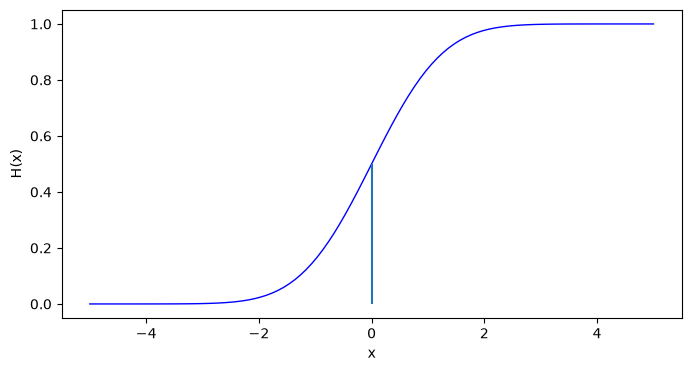

In [31]:
# CDF of a gaussian
f, ax = plt.subplots(nrows=1, figsize=(8, 4))
n = scipy.stats.norm(0, 1)
x = np.linspace(-5, 5, 100)
g_cdf = n.cdf(x)
ax.plot(x, g_cdf, lw=1, color="blue")
ax.vlines(0, 0, 0.5)
ax.set_xlabel('x'); ax.set_ylabel('H(x)')

*How to read up the percentile / probability from the CDF in python ?*

If you want to know for which value of $x$ we have a given probability/percentile, you may use the "percent point function" or `ppf` (i.e. the inverse of the `cdf`). To know for which $x$ one gets a specific $q$ ($0 < q < 1$), you may use the command: `scipy.stats.distrib.ppf(q)` (replace `distrib` by the name of the distribution you are interested in).

**Exercise:**

- Use `ppf` to calculate the interquartile range $q_{75} - q_{25}$ for a Gaussian/Normal distribution.

- Bonus: From the above definition, it is clear that:

$$
p(a < x < b\,| \,\mu, \sigma) = H(b \, | \,\mu, \sigma)-H(a \,| \, \mu, \sigma)
$$

Derive the probability $p(\mu - M\,\sigma < x < \mu + M \, \sigma)$ for M = 1, 2, 3 and calculate its values with `scipy`.

In [32]:
# Answer
n = scipy.stats.norm(0, 1)
print('q_25 and q_75 are %.3f , %.3f' % (n.ppf(0.25), n.ppf(0.75)))
print('The interquartile range is %.3f' % (n.ppf(0.75) - n.ppf(0.25)))

q_25 and q_75 are -0.674 , 0.674
The interquartile range is 1.349


In [33]:
n.ppf(np.array([0.25, 0.75]))

array([-0.67448975,  0.67448975])

This interquartile range is a bit larger than $\sigma$ for a gaussian distribution (${\rm IQR} \simeq 1.35\,\sigma$).

**Answer from BONUS**:
If we write the probability explicitly, we have:

$$
p(\mu - M\,\sigma< x < \mu + M\,\sigma \,| \,\mu, \sigma) = \frac{1}{2}~\left( 1 + {\rm erf} \left( \frac{|M|}{\sqrt{2}} \right)  \right) - \frac{1}{2}~\left( 1 - {\rm erf} \left( \frac{|M|}{\sqrt{2}} \right)  \right) = {\rm erf}(M/\sqrt{2})
$$

In [34]:
from scipy.special import erf

for M in [1, 2, 3]:
    print('p(mu - %i sigma < x < mu + %i sigma) = %.4f  (check with the cdf: %.4f)' % (M, M, erf(M / np.sqrt(2)), n.cdf(M) - n.cdf(-M)))

p(mu - 1 sigma < x < mu + 1 sigma) = 0.6827  (check with the cdf: 0.6827)
p(mu - 2 sigma < x < mu + 2 sigma) = 0.9545  (check with the cdf: 0.9545)
p(mu - 3 sigma < x < mu + 3 sigma) = 0.9973  (check with the cdf: 0.9973)


## Intermezzo: Descriptive statistics

This section is *not* mandatory if you fulfil the prerequisites for this course. However, if you do not feel comfortable with the concepts we have reviewed above, consider running the following notebooks:

- To review the **properties of probability distribution functions** (mean, standard deviation, variance, skewness, ...), go to the notebook [Descriptive_statistics_01.ipynb](Descriptive_statistics_01.ipynb).

- To **better understand visually the link between PDF and CDF**, and do an interactive tour of the characteristics and properties of **common distributions** encountered in science, then run the Notebook [Descriptive_statistics_02.ipynb](Descriptive_statistics_02.ipynb).

## Summary

We have reviewed basic statistical concepts and quantities, and how to use them in python. In particular:
- basic probability concepts: a sample space, a realisation, an event, a conditional probability (i.e. $p(A|B)$ is the probability of $A$ given $B$), and Bayes' theorem.
- the probability combination rules.
- what is a **random variable** (this is a key concept!), and how to generate and manipulate random variables with numpy using a generator `rng = np.random.default_rng(seed)`: `rng.random()`, `rng.integers()`, `rng.choice()`, `rng.permutation()`. The seed makes the results reproducible; the legacy `np.random.seed(value)` / `np.random.randint()` interface acts on a hidden global state.
- Probability density function (pdf) and cumulative distribution function (CDF) (you *need* to understand what these functions are very well!). A density is not a probability: only its integral over an interval is.
- How to manipulate distributions with `scipy.stats`. For example, to work with a gaussian, and subsequently calculate pdf, cdf, ... or draw samples: `g = scipy.stats.norm()` followed by `g.pdf(x)` to get a pdf evaluated at values x (single value or array), `g.cdf(x)` for the cdf, `g.rvs(size, random_state=rng)` for a random sample. `loc` and `scale` shift and stretch the standardised distribution; they are the mean and the std only for the gaussian.
- How to calculate an interquartile range based on the cdf of a function, using the inverse of a cdf, the ppf or percent point function (`scipy.stats.mydistribution.ppf()`).
- Use `scipy.special` to calculate special functions, in particular `scipy.special.erf()` which is the Gauss error function.

## X. References and supplementary material:  <a class="anchor" id="X"></a>

* **Chapter 1** (1.2), **Chapter 3** (3.1, 3.2) and **Chapter 4** (4.1 to 4.3) of the book <a class="anchor" id="book"></a> *Statistics, data mining and Machine learning in astronomy* by Z. Ivezic et al., Princeton Series in Modern Astronomy.

* Youtube video about Random variable and PDF: https://www.youtube.com/watch?v=9KVR1hJ8SxI : first 7 minutes
* Youtube video about CDF and its link to PDF: https://www.youtube.com/watch?v=4BswLMKgXzU : first 6 minutes

* *All of statistics: a concise course in statistical inference*, Wasserman 2004 <a class="anchor" id="WAS04"></a> (see also errata in http://www.stat.cmu.edu/~larry/all-of-statistics/).

* *Statistics in theory and Practice*, Lupton 1993 <a class="anchor" id="LUP93"></a>: **Chapter 2**

* [Numerical recipes](http://www2.units.it/ipl/students_area/imm2/files/Numerical_Recipes.pdf) by Press et al., Cambridge University Press: **Chapter 15**, **Chapter 18.7**

* numpy documentation on random generators: https://numpy.org/doc/stable/reference/random/index.html